In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/dataset.csv', encoding='latin-1')
df = df[['v1', 'v2']].rename(columns={'v1': 'label', 'v2': 'message'})

df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})

print(f'Shape : {df.shape}')
print(f'Class Balance: {df['label'].value_counts()}')
df.head()


Shape : (5572, 3)
Class Balance: label
ham     4825
spam     747
Name: count, dtype: int64


,label,message,label_num
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


C:\Users\TANISH N JAY\AppData\Local\Temp\ipykernel_20152\1884211354.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='label', data=df, palette={'ham' : "#3FED1C", 'spam': '#F44747'})


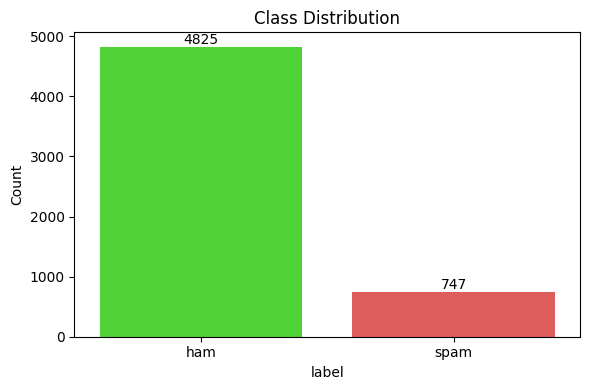

In [4]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='label', data=df, palette={'ham' : "#3FED1C", 'spam': '#F44747'})
plt.title('Class Distribution')
plt.ylabel('Count')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width()/2., p.get_height()),
                ha='center', va='bottom')
plt.tight_layout()
plt.savefig('../results/class_balance.png')
plt.show()

In [6]:
SPAM_KEYWORDS = ['free', 'win', 'winner', 'prize', 'claim',
                 'urgent', 'cash', 'offer', 'call', 'text',
                 'mobile', 'won', 'awarded', 'guaranteed']

def extract_features(text):
    text_str = str(text)
    words = text_str.split()
    letters = [c for c in text_str if c.isalpha()]
    return {
        'msg_length': len(text_str),
        'word_count': len(words),
        'digit_count': sum(c.isdigit() for c in text_str),
        'special_char_count': sum(c in '!$?' for c in text_str),
        'uppercase_ratio': sum(c.isupper() for c in letters) / max(len(letters), 1),
        'spam_keywords': sum(w.lower() in SPAM_KEYWORDS for w in words)
    }
features = df['message'].apply(extract_features)
feat_df = pd.DataFrame(features.tolist())
feat_df['label'] = df['label_num'].values
print(f'Feature Matrix Shape: {feat_df.shape}')
feat_df.head()

Feature Matrix Shape: (5572, 7)


,msg_length,word_count,digit_count,special_char_count,uppercase_ratio,spam_keywords,label
0,111,20,0,0,0.036145,0,0
1,29,6,0,0,0.111111,0,0
2,155,28,25,0,0.103093,3,1
3,49,11,0,0,0.060606,0,0
4,61,13,0,0,0.042553,0,0


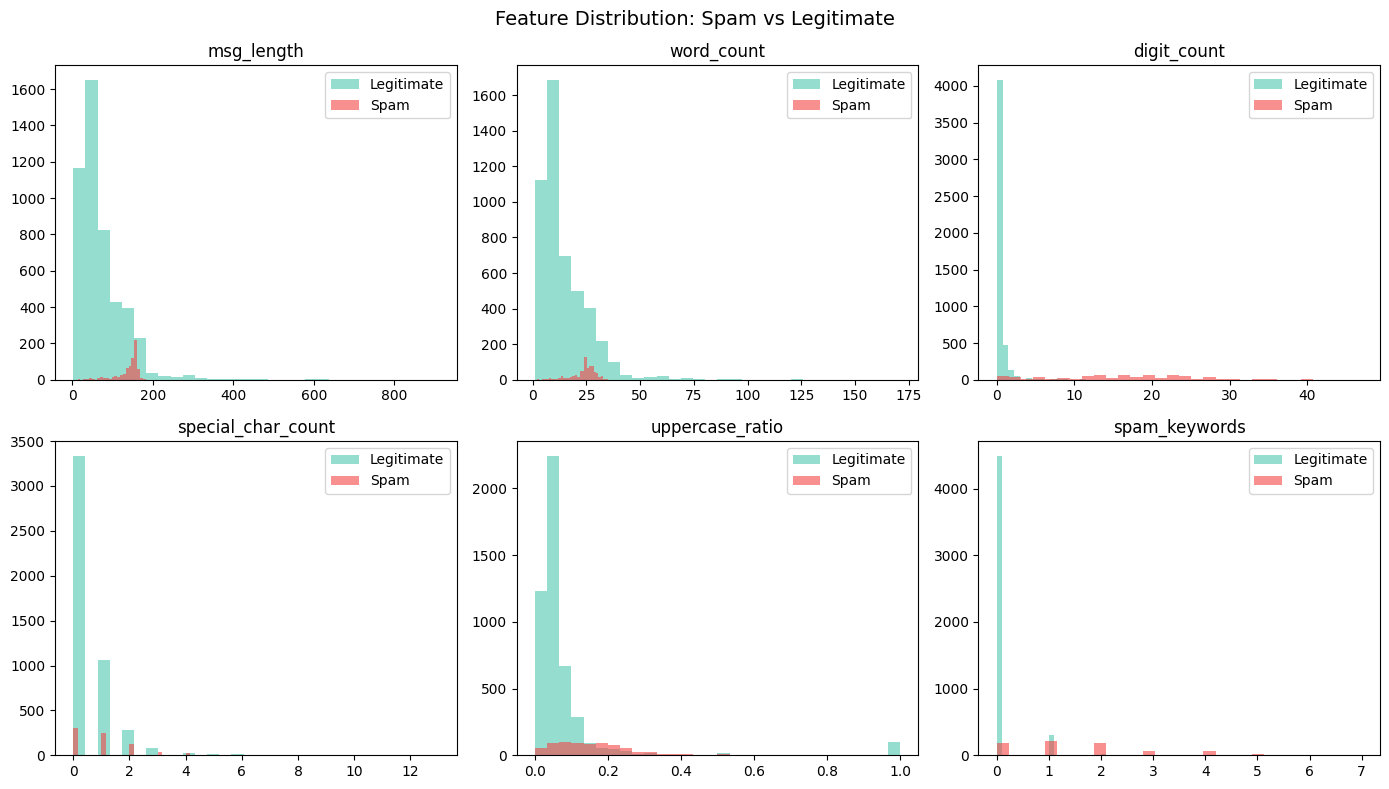

In [8]:
feature_cols = ['msg_length', 'word_count', 'digit_count',
                'special_char_count', 'uppercase_ratio', 'spam_keywords']
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, feat in enumerate(feature_cols):
    ham_vals = feat_df[feat_df['label'] == 0][feat]
    spam_vals = feat_df[feat_df['label'] == 1][feat]
    axes[i].hist(ham_vals, bins=30, alpha=0.6, color='#4EC9B0',label='Legitimate')
    axes[i].hist(spam_vals, bins=30, alpha=0.6, color='#F44747', label='Spam')
    axes[i].set_title(feat)
    axes[i].legend()

plt.suptitle('Feature Distribution: Spam vs Legitimate', fontsize=14)
plt.tight_layout()
plt.savefig('../results/feature_distribution.png')
plt.show()

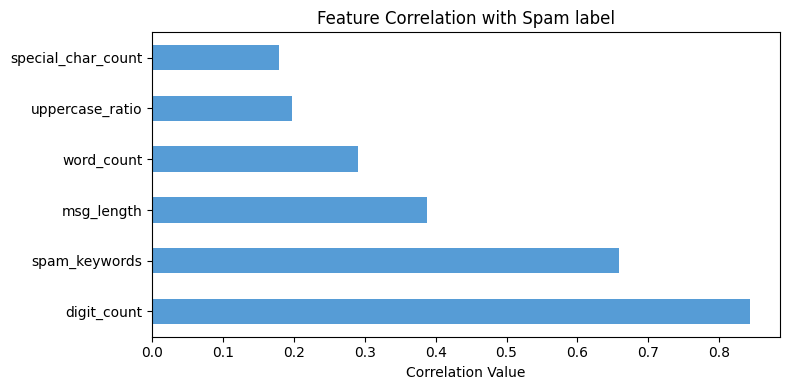

Top features:
 digit_count           0.843589
spam_keywords         0.659186
msg_length            0.387285
word_count            0.290263
uppercase_ratio       0.196881
special_char_count    0.179699
Name: label, dtype: float64


In [13]:
corr = feat_df.corr()['label'].drop('label').abs().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
corr.plot(kind='barh', color='#569CD6')
plt.title('Feature Correlation with Spam label')
plt.xlabel('Correlation Value')
plt.tight_layout()
plt.savefig('../results/feature_correlation.png')
plt.show()
print('Top features:\n', corr)

In [14]:
feat_df.to_csv('../data/features.csv', index=False)
print('feautures.csv saved')
print(f'Final shape: {feat_df.shape}')
print(f'Missing Values: {feat_df.isnull().sum().sum()}')

feautures.csv saved
Final shape: (5572, 7)
Missing Values: 0
